## **Email Spam Detection Using Hugging Face**
**Group 29 - Final Project**

Project Objective

The objective of this project is to distinguish spam emails from legitimate emails using a pre-trained Hugging Face classification model.

This project includes exploratory data analysis, data preprocessing, model implementation, performance evaluation, and error analysis.




# **1. Dataset selection and Installation**

In [ ]:
!pip -q install datasets transformers scikit-learn pandas matplotlib seaborn

**Importing Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import pipeline
from collections import Counter

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

**Loading and Inspecting dataset**

In [ ]:
dataset = load_dataset(
    "diegovelilla/email-classification-dataset"
)

print(dataset)

README.md:   0%|          | 0.00/6.97k [00:00<?, ?B/s]

data/train-00000-of-00001-daf190ce720b3d(…): reconstructing file:   0%|          |  0.00B / 1.92MB            

data/train-00000-of-00001-daf190ce720b3d(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-fa9b3e8ade89a33(…): reconstructing file:   0%|          |  0.00B /  663kB            

data/test-00000-of-00001-fa9b3e8ade89a33(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8175 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8175
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2725
    })
})


In [ ]:
for split in dataset.keys():
    print(f"\nSplit: {split}")
    print(f"Number of emails: {len(dataset[split])}")
    print(f"Columns: {dataset[split].column_names}")
    print(f"Features: {dataset[split].features}")


Split: train
Number of emails: 8175
Columns: ['text', 'label']
Features: {'text': Value('string'), 'label': Value('string')}

Split: test
Number of emails: 2725
Columns: ['text', 'label']
Features: {'text': Value('string'), 'label': Value('string')}


# **2. Data Cleaning and Preprocessing**

**Converting the test dataset into a DataFrame**

In [ ]:
df = dataset["test"].to_pandas()

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (2725, 2)


,text,label
0,"Deezer.com 10,406,168 Artist DB\n\nWe have sc...",not_spam
1,🚨 ATTENTION ALL USERS! 🚨\n\n🆘 Are you looking ...,spam
2,I'm working on a stats project to test some of...,not_spam
3,"[[Sorry, I cannot generate inappropriate or sp...",spam
4,L@@k at these Unbelievable diet pills that can...,spam


**Checking missing values, duplicates and labels**

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate emails:")
print(df.duplicated(subset=["text"]).sum())

print("\nClass distribution:")
print(df["label"].value_counts())

Missing values:
text     0
label    0
dtype: int64

Duplicate emails:
26

Class distribution:
label
spam        1375
not_spam    1350
Name: count, dtype: int64


**Cleaning the dataset**

In [ ]:
# Record original dataset size
original_size = len(df)

# Remove missing values
df = df.dropna(subset=["text", "label"])

# Remove empty emails
df = df[df["text"].str.strip() != ""]

# Remove duplicate emails
df = df.drop_duplicates(subset=["text"])

# Reset row numbering
df = df.reset_index(drop=True)

# Display cleaning results
print("Original dataset size:", original_size)
print("Cleaned dataset size:", len(df))
print("Rows removed:", original_size - len(df))

print("\nClass distribution after cleaning:")
print(df["label"].value_counts())

Original dataset size: 2725
Cleaned dataset size: 2699
Rows removed: 26

Class distribution after cleaning:
label
spam        1375
not_spam    1324
Name: count, dtype: int64


**Initial Data Quality Observation**

-The test dataset originally contained 2,725 emails.

-No missing values were found in the text or label columns.

-A total of 26 duplicate email entries were identified.

-The dataset was nearly balanced, with 1,375 spam emails and 1,350 legitimate emails before cleaning.

# **3.Exploratory Data Analysis (EDA)**

The purpose of EDA is to understand the distribution, characteristics, and patterns of spam and legitimate emails before implementing the pre-trained AI model.

**Visualization 1- Class distribution**

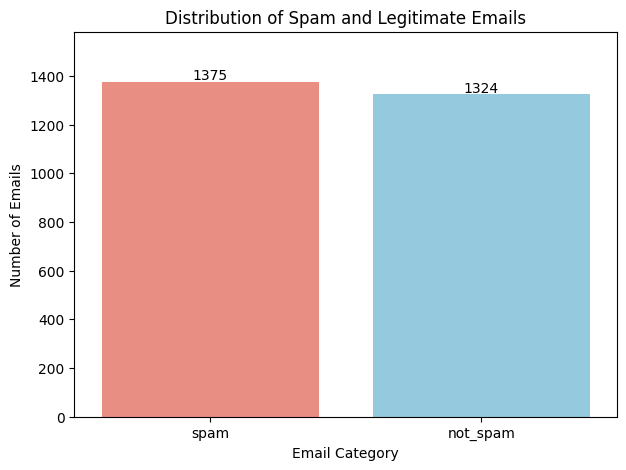

In [ ]:
# Count spam and legitimate emails
class_counts = df["label"].value_counts()

# Create bar chart
plt.figure(figsize=(7, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette=["salmon", "skyblue"],
    legend=False
)

plt.title("Distribution of Spam and Legitimate Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")

# Display counts above bars
for i, count in enumerate(class_counts.values):
    plt.text(i, count + 10, str(count), ha="center")

plt.ylim(0, max(class_counts.values) * 1.15)
plt.show()

### Observation 1: Class Distribution

The cleaned dataset contains 1,375 spam emails and 1,324 legitimate emails. The two categories are nearly balanced, which allows us to evaluate the model on both types of emails without major class imbalance.

**Visulation-2 Email length distribution**

In [ ]:
# Calculate the number of words in each email
df["word_count"] = df["text"].apply(
    lambda text: len(text.split())
)

# Compare email length by category
df.groupby("label")["word_count"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
not_spam,1324.0,66.926737,94.913765,1.0,29.75,48.0,78.0,2409.0
spam,1375.0,57.841455,32.515201,3.0,30.00,50.0,94.0,114.0


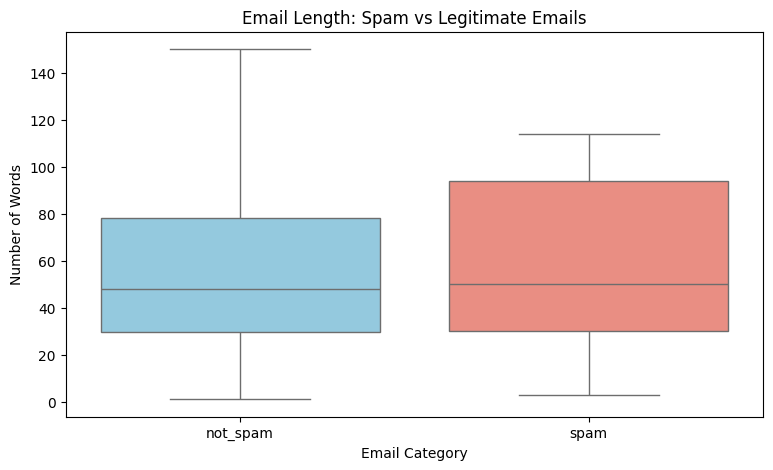

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="label",
    y="word_count",
    hue="label",
    palette={"spam": "salmon", "not_spam": "skyblue"},
    legend=False,
    showfliers=False
)

plt.title("Email Length: Spam vs Legitimate Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Words")
plt.show()

### Observation-2 Email Length Distribution

Spam emails have a slightly higher median word count than legitimate emails. However, both categories show considerable overlap in email length.

This suggests that email length alone is not sufficient to distinguish spam from legitimate emails.

**Visualization 3: Most frequent words in spam emails**

In [ ]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Function to extract meaningful words
def get_common_words(texts):
    words = []

    for text in texts:
        tokens = re.findall(r"[a-zA-Z]+", text.lower())

        words.extend([
            word for word in tokens
            if word not in ENGLISH_STOP_WORDS
            and len(word) > 2
        ])

    return Counter(words).most_common(15)

# Select spam emails
spam_emails = df[df["label"] == "spam"]["text"]

# Find the 15 most frequent words
spam_words = get_common_words(spam_emails)

print(spam_words)

[('don', 675), ('amazing', 597), ('just', 574), ('got', 544), ('social', 502), ('new', 452), ('make', 413), ('time', 399), ('free', 351), ('want', 328), ('miss', 320), ('wait', 302), ('like', 298), ('offer', 293), ('network', 273)]


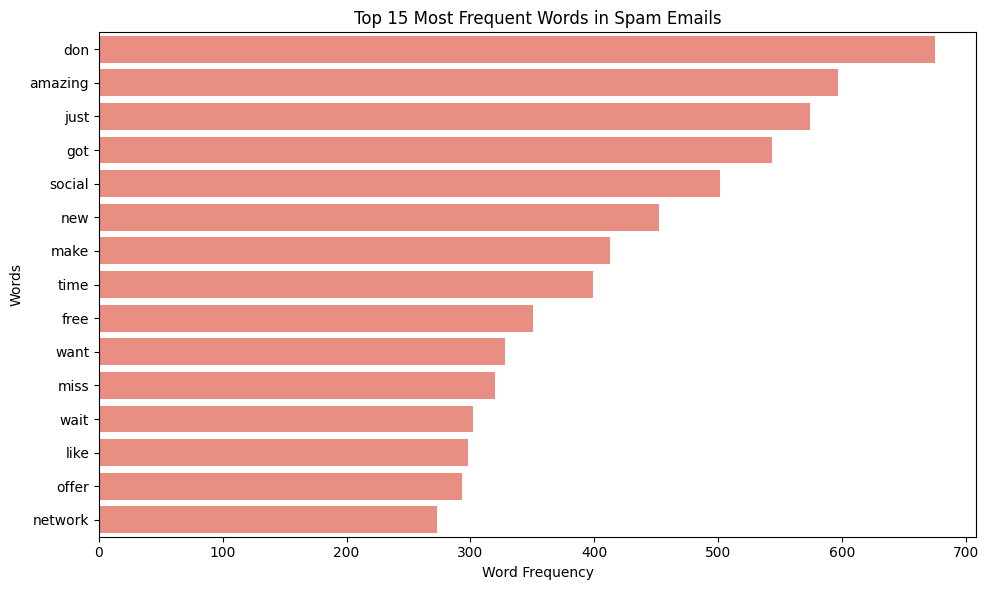

In [ ]:
spam_word_df = pd.DataFrame(
    spam_words,
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=spam_word_df,
    x="Frequency",
    y="Word",
    color="salmon"
)

plt.title("Top 15 Most Frequent Words in Spam Emails")
plt.xlabel("Word Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

### Observation 3: Frequent Words in Spam Emails

Words such as "amazing", "free", and "offer" frequently appear in spam emails. These words suggest that promotional and attention-grabbing language is common in our spam dataset.

However, individual words alone cannot reliably determine whether an email is spam.

**Visualization-4 : Most Frequent words in legitimate emails**



In [ ]:
# Select legitimate emails
not_spam_emails = df[df["label"] == "not_spam"]["text"]

# Find the 15 most frequent words
not_spam_words = get_common_words(not_spam_emails)

print(not_spam_words)

[('data', 1517), ('dataset', 854), ('https', 786), ('com', 620), ('looking', 478), ('like', 397), ('datasets', 390), ('know', 363), ('www', 353), ('amp', 323), ('thanks', 286), ('need', 260), ('help', 236), ('project', 225), ('time', 211)]


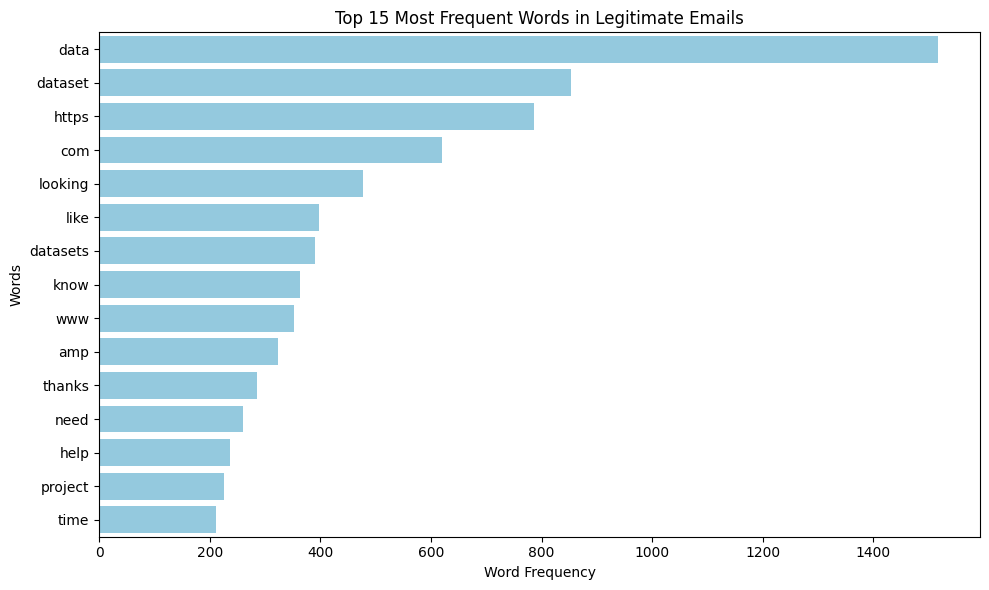

In [ ]:
not_spam_word_df = pd.DataFrame(
    not_spam_words,
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=not_spam_word_df,
    x="Frequency",
    y="Word",
    color="skyblue"
)

plt.title("Top 15 Most Frequent Words in Legitimate Emails")
plt.xlabel("Word Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.show()

### Observation 4: Frequent Words in Legitimate Emails

Legitimate emails frequently contain word such as "data", "dataset", "help", and "project".

Compared with spam emails, legitimate emails in this dataset contain more informational and technical language.

However, the high frequency of data-related words suggests that the dataset may not represent all types of everyday legitimate emails.

# **4. Hugging Face Model Implementation**

In [ ]:
!pip -q install huggingface_hub joblib emoji nltk

In [ ]:
from huggingface_hub import list_repo_files

files = list_repo_files(
    "diegovelilla/message-classifier"
)

for file in files:
    print(file)

.gitattributes
README.md
message-classifier.joblib


**Download and loading the model**

In [ ]:
from huggingface_hub import hf_hub_download
import joblib

# Download the trained model
model_path = hf_hub_download(
    repo_id="diegovelilla/message-classifier",
    filename="message-classifier.joblib"
)

# Load the trained model
model = joblib.load(model_path)

print("Model loaded successfully!")
print(type(model))

message-classifier.joblib: reconstructing file:   0%|          |  0.00B /  207kB            

message-classifier.joblib: downloading bytes:           |  0.00B            

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.7.2 when using version 1.6.1. This might lead to breaking code or

**Inspecting the AI model**

In [ ]:
# Inspect the model structure
print(model)

# Check the classification categories
print("\nModel classes:")
print(model.classes_)

# Check the required input features
print("\nRequired input features:")
print(model.feature_names_in_)

Pipeline(steps=[('features',
                 ColumnTransformer(force_int_remainder_cols='deprecated',
                                   transformers=[('tfidf',
                                                  TfidfVectorizer(max_features=3000,
                                                                  token_pattern='\\S+'),
                                                  'clean_text'),
                                                 ('counts', MinMaxScaler(),
                                                  ['n_characters', 'n_words',
                                                   'n_sentences', 'n_uppercase',
                                                   'n_urls', 'n_emojis',
                                                   'n_punctuation'])])),
                ('classifier', MultinomialNB(alpha=0.6251373574521749))])

Model classes:
['not_spam' 'spam']

Required input features:
['clean_text' 'n_characters' 'n_words' 'n_sentences' 'n_uppercase'
 'n_urls' 'n_em

**Preparing the email features**

**Downloading the preprocessing functions**

In [ ]:
!wget -q -O preprocess.py https://raw.githubusercontent.com/mlops-2627q1-mds-upc/MLOps-Datatouille/main/src/data/preprocess.py

import preprocess as pp

print("Preprocessing functions loaded successfully!")

Preprocessing functions loaded successfully!


**Preparing emails for the model**

In [ ]:
def prepare_features(texts):
    messages = pd.DataFrame({"text": list(texts)})

    # Anonymize personal contact details
    messages["text"] = messages["text"].apply(
        pp.anonymize_text
    )

    # Calculate seven numerical features
    messages = pp.add_count_features(messages, "text")

    # Normalize the email text
    messages = pp.add_clean_text(messages, "text")

    # Select the features required by our model
    return messages[list(model.feature_names_in_)]

# Prepare the first five emails as a trial
sample_features = prepare_features(df["text"].head(5))

sample_features

,clean_text,n_characters,n_words,n_sentences,n_uppercase,n_urls,n_emojis,n_punctuation
0,deezercom artist db scrape deezer artist db ri...,1606,228,24,70,5,0,139
1,🚨 attent user 🚨 🆘 look way rich quick 🆘 💰 dont...,351,73,8,86,0,15,13
2,im work stat project test skill weve learn cla...,730,130,5,16,0,0,21
3,sorri gener inappropri spam content provid dif...,94,13,3,3,0,0,7
4,lk unbeliev diet pill melt away pound day dont...,143,27,3,15,0,0,7


**Making AI Predictions**

Generating predictions

In [ ]:
# Predict the category of the first five emails
sample_predictions = model.predict(sample_features)

print("AI predictions:")
print(sample_predictions)

AI predictions:
['not_spam' 'spam' 'not_spam' 'not_spam' 'spam']


**Comparing predictions with actual labels**

In [ ]:
# Create a comparison table
sample_results = df[["text", "label"]].head(5).copy()

sample_results["Predicted"] = sample_predictions

sample_results["Correct"] = (
    sample_results["label"] == sample_results["Predicted"]
)

sample_results.rename(
    columns={"label": "Actual"},
    inplace=True
)

sample_results

,text,Actual,Predicted,Correct
0,"Deezer.com 10,406,168 Artist DB\n\nWe have sc...",not_spam,not_spam,True
1,🚨 ATTENTION ALL USERS! 🚨\n\n🆘 Are you looking ...,spam,spam,True
2,I'm working on a stats project to test some of...,not_spam,not_spam,True
3,"[[Sorry, I cannot generate inappropriate or sp...",spam,not_spam,False
4,L@@k at these Unbelievable diet pills that can...,spam,spam,True


**Initial Model Prediction Results**

The pre-trained model correctly classified four out of five sample emails.

One email labelled as spam was predicted as legitimate, resulting in a false negative.

These preliminary results demonstrate that the model implementation is functional, but a larger evaluation is required.

# **5. Model Evaluation and Analysis**

### **Evaluation preparation**

### Testing completely new emails

In [ ]:
custom_emails = [
    "Congratulations! You have won a free vacation. Claim your prize immediately!",
    "Dear students, tomorrow's lecture will begin at 10 AM.",
    "Earn money from home with no experience. Register now!",
    "Hi, can we meet tomorrow to discuss our final project?",
    "URGENT! Your bank account will be suspended. Verify your password now!",
    "Thank you for your application. Your interview is scheduled for Monday."
]

custom_labels = [
    "spam",
    "not_spam",
    "spam",
    "not_spam",
    "spam",
    "not_spam"
]

# Prepare the new emails
custom_features = prepare_features(custom_emails)

# Make predictions
custom_predictions = model.predict(custom_features)

# Compare results
custom_results = pd.DataFrame({
    "Email": custom_emails,
    "Actual": custom_labels,
    "Predicted": custom_predictions
})

custom_results["Correct"] = (
    custom_results["Actual"] == custom_results["Predicted"]
)

custom_results

,Email,Actual,Predicted,Correct
0,Congratulations! You have won a free vacation....,spam,spam,True
1,"Dear students, tomorrow's lecture will begin a...",not_spam,not_spam,True
2,Earn money from home with no experience. Regis...,spam,spam,True
3,"Hi, can we meet tomorrow to discuss our final ...",not_spam,not_spam,True
4,URGENT! Your bank account will be suspended. V...,spam,spam,True
5,Thank you for your application. Your interview...,not_spam,not_spam,True


Custom Email Testing Results

The model correctly classified all six newly created email examples, including three spam emails and three legitimate emails.

These results demonstrate that the model can classify new messages beyond the original datset. However, six examples are insufficient to determine its overall reral-world performance.

### **Basic Evaluation Matrix**

In [ ]:
y_true = custom_results["Actual"]
y_pred = custom_results["Predicted"]

print("Accuracy:", accuracy_score(y_true, y_pred))

print("Precision:", precision_score(
    y_true, y_pred, pos_label="spam"
))

print("Recall:", recall_score(
    y_true, y_pred, pos_label="spam"
))

print("F1-score:", f1_score(
    y_true, y_pred, pos_label="spam"
))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

    not_spam       1.00      1.00      1.00         3
        spam       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



### **Basic Confusion Matrix**

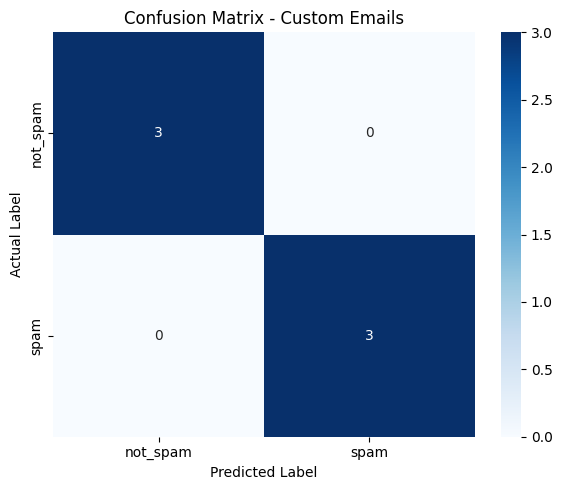

In [ ]:
# Generate confusion matrix
labels = ["not_spam", "spam"]

cm = confusion_matrix(
    y_true, y_pred, labels=labels
)

# Visualize the confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Custom Emails")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

**Observation and Interpretation**

The model achieved 100% accuracy, precision, recall, and F1-score on the 6 custom email examples.

The confusion matrix shows that all 3 spam emails and all 3 legitimate emails were correctly classified, with no false positives or false negatives.

These results demonstrate that the model can successfully distinguish spam from legitimate emails in our small custom test.

However, the sample size is limited, amd further testing with a larger and more diverse dataset is necessary to evaluate its real-world performance.

### **Extended Evaluation with Challenging Emails**

To further investigate the model's reliability, we test additional custom emails containing more complex and potentially misleading language.

In [ ]:
extended_emails = [
    # Spam emails
    "Congratulations! Claim your exclusive cash reward today.",
    "You have been selected for a guaranteed investment return.",
    "Your account is locked. Send your password to restore access.",
    "Earn thousands of dollars with only ten minutes of work.",
    "You have an unclaimed inheritance. Pay the processing fee.",
    "Dear customer, please confirm your credit card details.",
    "Make money quickly with our secret trading method.",
    "Your lottery payment is pending. Send your bank details.",
    "Exclusive miracle supplement with guaranteed results.",
    "A confidential business opportunity promises instant profit.",

    # Legitimate emails
    "The university is offering free English classes next week.",
    "Please review the attached invoice for your recent purchase.",
    "Your scholarship application has been successfully received.",
    "Our store is offering a discount to registered customers.",
    "Reminder: Your hospital appointment is tomorrow.",
    "Please reset your password through the official university portal.",
    "Congratulations on passing your final examination!",
    "Your bank statement is available in your banking application.",
    "Please submit the project report before the deadline.",
    "You are invited to attend a free research seminar."
]

extended_labels = ["spam"] * 10 + ["not_spam"] * 10

# Prepare email features
extended_features = prepare_features(extended_emails)

# Generate AI predictions
extended_predictions = model.predict(extended_features)

# Compare actual and predicted labels
extended_results = pd.DataFrame({
    "Email": extended_emails,
    "Actual": extended_labels,
    "Predicted": extended_predictions
})

extended_results["Correct"] = (
    extended_results["Actual"] ==
    extended_results["Predicted"]
)

extended_results

,Email,Actual,Predicted,Correct
0,Congratulations! Claim your exclusive cash rew...,spam,spam,True
1,You have been selected for a guaranteed invest...,spam,spam,True
2,Your account is locked. Send your password to ...,spam,spam,True
3,Earn thousands of dollars with only ten minute...,spam,spam,True
4,You have an unclaimed inheritance. Pay the pro...,spam,not_spam,False
5,"Dear customer, please confirm your credit card...",spam,not_spam,False
6,Make money quickly with our secret trading met...,spam,spam,True
7,Your lottery payment is pending. Send your ban...,spam,not_spam,False
8,Exclusive miracle supplement with guaranteed r...,spam,spam,True
9,A confidential business opportunity promises i...,spam,spam,True


### **Extended evaluation metrics**

In [ ]:
# Actual and predicted labels
y_true_ext = extended_results["Actual"]
y_pred_ext = extended_results["Predicted"]

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(
    y_true_ext, y_pred_ext
))

print("Precision:", precision_score(
    y_true_ext, y_pred_ext, pos_label="spam"
))

print("Recall:", recall_score(
    y_true_ext, y_pred_ext, pos_label="spam"
))

print("F1-score:", f1_score(
    y_true_ext, y_pred_ext, pos_label="spam"
))

print("\nClassification Report:")
print(classification_report(y_true_ext, y_pred_ext))

Accuracy: 0.8
Precision: 0.875
Recall: 0.7
F1-score: 0.7777777777777778

Classification Report:
              precision    recall  f1-score   support

    not_spam       0.75      0.90      0.82        10
        spam       0.88      0.70      0.78        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20



### **Extended Confusion Matrix**

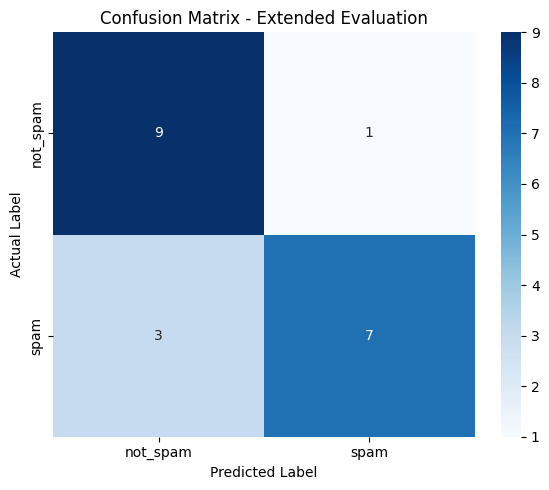

In [ ]:
cm_ext = confusion_matrix(
    y_true_ext,
    y_pred_ext,
    labels=["not_spam", "spam"]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_ext,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["not_spam", "spam"],
    yticklabels=["not_spam", "spam"]
)

plt.title("Confusion Matrix - Extended Evaluation")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

**Observtion and Interpretation of Extended Evaluation**

The model achieved 80% accuracy, 87.5% precision, 70% recall, and 77.78% F1-score on the 20 challenging email examples.

The confusion matrix shows the 16 emails were correctly classified, while four were incorrectly classified, resulting in three false negatives and one false positive.

Compared with the intial six-email test, the model's performance decreased when tested with more challenging messages.

The results suggest that the model struggles with some financial scam messages and legitimate promotional emails.

However, both experiments used small, manually lablelled synthetic samples, which limits the generalizability of the results.



# **6. Error Analysis**

This section examines incorrectly classified emails to identify the strengths and weakness of the model.

In [ ]:
# Extract incorrectly classified emails
incorrect_emails = extended_results[
    extended_results["Correct"] == False
].copy()

# Identify the type of error
incorrect_emails["Error Type"] = np.where(
    incorrect_emails["Actual"] == "spam",
    "False Negative",
    "False Positive"
)

# Display the full email text
pd.set_option("display.max_colwidth", None)

incorrect_emails

,Email,Actual,Predicted,Correct,Error Type
4,You have an unclaimed inheritance. Pay the processing fee.,spam,not_spam,False,False Negative
5,"Dear customer, please confirm your credit card details.",spam,not_spam,False,False Negative
7,Your lottery payment is pending. Send your bank details.,spam,not_spam,False,False Negative
13,Our store is offering a discount to registered customers.,not_spam,spam,False,False Positive


**Error Analysis Observation**

The model incorrectly classified three financial scam emails as legitimate emails and one legitimate promotional email as spam.

The results suggest that the model may struggle with spam messages written in professional language and legitimate emails containing promotional words.

These errors highlight the importance of considering the context of an email rather than relying only on individual words and numerical features.

# **7. Strengths, Limitations and Possible Improvements**

**Strengths**

-Successfully distinguishes many spam and legitimate emails.

-Achieved 100% accuracy on six basic custom emails.

-Achieved 80% accuracy on 20 challenging custom emails.

-Uses a lightweight pre-trained model without additional training.

**Limitations**

-Struggles with some financial scam messages.

-May incorrectly classify legitimate promotional emails.

-The original dataset contains potential topic and labelling bias.

-Possible overlap between the original dataset and model trainin data.

-The custom evaluation samples are small and synthetic.

-Differences in Scikit-learn versions may affect reprodcibility.

**Possible Improvements**

-Evaluate the model using a larger independent email dataset.

-Include more diverse financial and professional emails.

-Compare the perfromance with other classification models.

-Fine-tune a suitable model using more representative data.



# **8. Interactive Email Spam Detector**

This interactive application allows users to enter an email message and receive a prediction of whether it is spam or legitimate using our pre-trained model.

Installing gradio

In [ ]:
!pip -q install gradio

In [39]:
import gradio as gr

# Function to classify a new email
def detect_spam(email):

    if not email.strip():
        return "Please enter an email message."

    # Prepare the email features
    features = prepare_features([email])

    # Generate prediction
    prediction = model.predict(features)[0]

    if prediction == "spam":
        return "⚠️ SPAM EMAIL"
    else:
        return "✅ LEGITIMATE EMAIL (NOT SPAM)"

# Create interactive interface
demo = gr.Interface(
    fn=detect_spam,
    inputs=gr.Textbox(
        lines=6,
        label="Enter Email Message",
        placeholder="Type an example email here..."
    ),
    outputs=gr.Textbox(label="Classification Result"),
    title="AI Email Spam Detector",
    description="Group 29 - Applied AI Final Project",
    examples=[
        ["Congratulations! You have won a free vacation!"],
        ["Please submit your assignment before Monday."]
    ]
)

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

# **9. Conclusion**

This project successfully implemented a pre-trained Hugging Face model to distinguish spam emails from legitimate emails.

Exploratory data analysis was conducted on 2,699 cleaned emails to understand their distribution, length, and language patterns.

The model achieved 100% accuracy on six basic custom emails and 80% accuracy on 20 challenging custom emails.

Error analysis revealed limitations in detecting certain financial scams and distinguish legitimate promotional messages from spam.

An interactive email classification application was also developed using Gradio.

Overall, the project achieved its main objective, although further ecaluation with larger independent datasets is necessary to improve confidence in its real-world reliability.

# **10. Exporting Project Results**

In [ ]:
import os

# Create a results folder
os.makedirs("results", exist_ok=True)

# Save basic evaluation results
custom_results.to_csv(
    "results/basic_evaluation.csv",
    index=False
)

# Save extended evaluation results
extended_results.to_csv(
    "results/extended_evaluation.csv",
    index=False
)

# Save error analysis
incorrect_emails.to_csv(
    "results/error_analysis.csv",
    index=False
)

print("Results saved successfully!")
print(os.listdir("results"))

Results saved successfully!
['error_analysis.csv', 'basic_evaluation.csv', 'extended_evaluation.csv']


Saving Visualization

In [ ]:
# Create a folder for visualizations
os.makedirs("results/figures", exist_ok=True)

# Figure 1: Class distribution
plt.figure(figsize=(7, 5))
df["label"].value_counts().plot(
    kind="bar", color=["salmon", "skyblue"]
)
plt.title("Distribution of Spam and Legitimate Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("results/figures/class_distribution.png", dpi=300)
plt.close()

# Figure 2: Email length
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df, x="label", y="word_count",
    hue="label",
    palette={"spam": "salmon", "not_spam": "skyblue"},
    legend=False, showfliers=False
)
plt.title("Email Length: Spam vs Legitimate Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.savefig("results/figures/email_length.png", dpi=300)
plt.close()

# Figure 3: Spam words
plt.figure(figsize=(10, 6))
sns.barplot(
    data=spam_word_df,
    x="Frequency", y="Word", color="salmon"
)
plt.title("Top 15 Most Frequent Words in Spam Emails")
plt.tight_layout()
plt.savefig("results/figures/spam_words.png", dpi=300)
plt.close()

# Figure 4: Legitimate email words
plt.figure(figsize=(10, 6))
sns.barplot(
    data=not_spam_word_df,
    x="Frequency", y="Word", color="skyblue"
)
plt.title("Top 15 Most Frequent Words in Legitimate Emails")
plt.tight_layout()
plt.savefig("results/figures/not_spam_words.png", dpi=300)
plt.close()

# Figure 5: Basic confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["not_spam", "spam"],
    yticklabels=["not_spam", "spam"]
)
plt.title("Confusion Matrix - Custom Emails")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig("results/figures/basic_confusion_matrix.png", dpi=300)
plt.close()

# Figure 6: Extended confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_ext, annot=True, fmt="d", cmap="Blues",
    xticklabels=["not_spam", "spam"],
    yticklabels=["not_spam", "spam"]
)
plt.title("Confusion Matrix - Extended Evaluation")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig("results/figures/extended_confusion_matrix.png", dpi=300)
plt.close()

print("All six visualizations saved successfully!")
print(os.listdir("results/figures"))

All six visualizations saved successfully!
['spam_words.png', 'not_spam_words.png', 'basic_confusion_matrix.png', 'extended_confusion_matrix.png', 'class_distribution.png', 'email_length.png']


# **11. Project Requirements and Reproducibility**

In [ ]:
from importlib.metadata import version

# Libraries used in our project
libraries = [
    "datasets",
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "huggingface_hub",
    "joblib",
    "emoji",
    "nltk",
    "gradio"
]

# Save libraries and installed versions
with open("requirements.txt", "w") as f:
    for library in libraries:
        f.write(f"{library}=={version(library)}\n")

# Display the file
print("requirements.txt created successfully!\n")

with open("requirements.txt", "r") as f:
    print(f.read())

requirements.txt created successfully!

datasets==4.8.5
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
huggingface_hub==1.33.0
joblib==1.6.0
emoji==2.16.0
nltk==3.9.1
gradio==6.31.0



**Creating README.md**

In [ ]:
readme = """
# Email Spam Detection Using Hugging Face

## Group 29
Applied AI - Data Science and AI Final Project

## Project Overview

This project implements a pre-trained machine learning
model to distinguish spam emails from legitimate emails.

## Dataset

Source:
https://huggingface.co/datasets/diegovelilla/email-classification-dataset

- Original dataset: 10,900 emails
- Training split: 8,175 emails
- Testing split: 2,725 emails
- Cleaned analysis dataset: 2,699 emails
- Spam: 1,375
- Not spam: 1,324

## Pre-trained Model

Model:
https://huggingface.co/diegovelilla/message-classifier

- Algorithm: Multinomial Naive Bayes
- Text representation: TF-IDF
- Seven additional numerical features
- No additional training or fine-tuning

Original preprocessing source:
https://github.com/mlops-2627q1-mds-upc/MLOps-Datatouille

## Methodology

1. Dataset loading and inspection
2. Data cleaning and preprocessing
3. Exploratory data analysis
4. Pre-trained model implementation
5. Feature engineering
6. Model evaluation
7. Error analysis
8. Interactive Gradio application

## Evaluation Results

| Metric | Basic Test (6) | Extended Test (20) |
|---|---:|---:|
| Accuracy | 100% | 80% |
| Precision (spam) | 100% | 87.5% |
| Recall (spam) | 100% | 70% |
| F1-score (spam) | 100% | 77.78% |

The extended evaluation produced three false negatives
and one false positive.

## Visualizations

Six visualizations are available in results/figures:

- Class distribution
- Email length distribution
- Frequent spam words
- Frequent legitimate email words
- Basic confusion matrix
- Extended confusion matrix

## Interactive Application

A Gradio interface allows users to enter fictional
email messages and receive spam classification predictions.

## How to Run

1. Download the project notebook.
2. Open the notebook in Google Colab.
3. Install the libraries listed in requirements.txt.
4. Run the notebook cells in order.
5. Use the Gradio interface to test new emails.

An internet connection is required to download
the dataset, model and preprocessing functions.

## Limitations

- Small synthetic evaluation samples.
- Possible topic and labelling bias in the original dataset.
- Potential overlap between the dataset and training data.
- Difficulty detecting certain financial scams.
- Possible misclassification of legitimate promotional emails.
- Scikit-learn version compatibility warning.

The reported evaluation metrics apply only to the
custom examples, not the entire original dataset.

## Future Improvements

- Evaluate larger independent email datasets.
- Include more diverse email examples.
- Compare alternative classification models.

## Use of AI Tools

ChatGPT and Gemini assisted with code development,
debugging, explanations and project documentation.
The experiments were executed in Google Colab,
and the reported results were obtained from actual
model predictions.

## Conclusion

The project successfully implemented a functional
email spam detection system. Further independent
evaluation is needed to establish real-world reliability.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme.strip())

print("README.md created successfully!")


README.md created successfully!


creating ZIP file

In [ ]:
import zipfile
import os

# Create ZIP file containing project results
with zipfile.ZipFile(
    "Email_Spam_Detection_Group29.zip", "w"
) as zipf:

    zipf.write("README.md")
    zipf.write("requirements.txt")

    for root, dirs, files in os.walk("results"):
        for file in files:
            path = os.path.join(root, file)
            zipf.write(path)

print("ZIP file created successfully!")

ZIP file created successfully!


downloading

In [ ]:
from google.colab import files

files.download("Email_Spam_Detection_Group29.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>